# 01 - Data quality and validation

## Objective
Turn the supplier CSV files into a validated research dataset with traceable source-row IDs.
This is stage 1 of 3: **raw data -> validated bars -> features and statistical research -> strategy hypotheses**.

## Inputs and execution
Run from the project directory. Configure the raw-data location in the next cell; later stages use only relative `artifacts/` paths.
Use Python 3.11+ with pandas, NumPy, SciPy, Matplotlib, PyArrow, Jinja2 and an IPython kernel.
Only the three notebooks are project source dependencies. Raw CSV files and generated artifacts need not be committed.

## Methodology
Preserved cleaning: assign a one-based data-row `ID` before sorting, remove only exact copies, then reconcile each `(symbol, date)` group.
Keep a field only when every distinct variant agrees; otherwise set that field to `NaN`. Keep the minimum original ID and export all source variants.
No forward filling, price adjustment, outlier deletion or winsorization is introduced.
`instrument` identifies the source file; `symbol` identifies a delivery contract within that file.

For GitHub, version only these three notebook files. `fut_data/`, `artifacts/` and the local virtual environment are data/runtime material, not required source contributions.

## Research configuration
All paths and validation constants are defined here. The dataset uses supplier-local, timezone-naive minute timestamps; a timezone is not inferred.
The 6% loss threshold controls review labels only, not row removal.

In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib
import json
import re
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAW_DIR = Path("fut_data")
ARTIFACT_DIR = Path("artifacts")
QUALITY_DIR = ARTIFACT_DIR / "quality"
CLEAN_PATH = ARTIFACT_DIR / "clean_market_data.parquet"
EXPECTED_FREQUENCY = pd.Timedelta(minutes=1)
REQUIRED_COLUMNS = ["date", "symbol", "open", "high", "low", "close", "volume", "money", "open_interest"]
OPTIONAL_COLUMNS = []  # No additional source fields were present in the existing dataset.
FIELDS = ["open", "high", "low", "close", "volume", "money", "open_interest"]
PRICES = ["open", "high", "low", "close"]
KEY = ["symbol", "date"]
SELECTION_KEY = ["date", "symbol"]
MINUTE = EXPECTED_FREQUENCY
LOSS_THRESHOLD_PCT = 6.0
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
PARAMETERS = {"move_floor_pct": 1.0, "mad_multiplier": 10.0, "minimum_reference_edges": 100}
INFERENCE_PARAMETERS = {"neighbor_days_each_side": 10, "maximum_calendar_distance_days": 45,
    "minimum_reference_days": 5, "expected_minute_frequency": .8, "break_minute_frequency": .2}
INTERVAL_COLUMNS = ["gap_ID", "symbol", "ID_before", "minute_before", "ID_after", "minute_after",
    "first_absent", "last_absent", "interval_minutes", "classification", "cross_midnight",
    "reference_days_min", "reference_days_max", "observed_fraction_min", "observed_fraction_max"]
for folder in [ARTIFACT_DIR, QUALITY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

def file_hash(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .18, "figure.dpi": 120})

def show_table(frame, title, rows=15):
    probability_columns = {"p value", "p_screen", "q_by", "p_hac20", "p_hac60"}
    formats = {column: (lambda value: "NA" if not np.isfinite(value) else "<1e-300" if value == 0 else f"{value:.2e}")
               for column in frame.columns if column in probability_columns}
    display(frame.head(rows).style.hide(axis="index").format(formats, precision=6, na_rep="NA")
        .set_caption(title).set_properties(**{"padding": "5px 8px", "font-size": "12px"})
        .set_table_styles([{"selector": "th", "props": [("white-space", "normal"), ("max-width", "150px")]}]))
    if len(frame) > rows:
        print(f"Showing {rows:,} of {len(frame):,} rows; the complete table is exported.")

## Raw-file discovery and schema validation
Discover all CSVs under the configured raw directory. Report schema problems before processing; missing columns are never fabricated.
Full date coverage and observation counts are reported after the streaming scan.

In [2]:
raw_paths = sorted(RAW_DIR.rglob("*.csv"))
if not raw_paths:
    raise FileNotFoundError(f"No raw market CSV files found in {RAW_DIR}. Configure RAW_DIR in Notebook 1.")
schema_rows = []
for path in raw_paths:
    columns = pd.read_csv(path, nrows=0).columns.tolist()
    schema_rows.append({"instrument": path.relative_to(RAW_DIR).as_posix(), "bytes": path.stat().st_size,
        "missing_required": ", ".join(sorted(set(REQUIRED_COLUMNS)-set(columns))),
        "unexpected_columns": ", ".join(sorted(set(columns)-set(REQUIRED_COLUMNS)-set(OPTIONAL_COLUMNS))),
        "source_columns": ", ".join(columns)})
schema_report = pd.DataFrame(schema_rows)
schema_report.to_csv(QUALITY_DIR / "schema_report.csv", index=False)
print(f"Raw files: {len(raw_paths):,}; instruments: {schema_report.instrument.nunique():,}")
print(f"Total source size: {schema_report.bytes.sum()/1024**3:.3f} GiB")
show_table(schema_report[["instrument", "bytes", "missing_required", "unexpected_columns"]], "Raw-file inventory")
if schema_report.missing_required.ne("").any() or schema_report.unexpected_columns.ne("").any():
    raise ValueError("Schema validation failed; inspect artifacts/quality/schema_report.csv before proceeding.")
source_hashes = {str(path): file_hash(path) for path in raw_paths}

Raw files: 77; instruments: 77
Total source size: 3.292 GiB


instrument,bytes,missing_required,unexpected_columns
A9999.XDCE.csv,92352408,,
AG9999.XSGE.csv,94317946,,
AL9999.XSGE.csv,113221835,,
AP9999.XZCE.csv,17327936,,
AU9999.XSGE.csv,110313437,,
B9999.XDCE.csv,82351760,,
BB9999.XDCE.csv,27730616,,
BC9999.XINE.csv,8279941,,
BU9999.XSGE.csv,53897668,,
C9999.XDCE.csv,79134105,,


Showing 15 of 77 rows; the complete table is exported.


## Source IDs, ordering and exact duplicates
Sort each file by timestamp and original ID. Equal timestamps keep their source order.
Full-row equality excludes the generated ID. Distinct rows sharing a contract and timestamp are conflicts, not disposable duplicates.

In [3]:
def prepare_data(raw: pd.DataFrame) -> dict:
    if "ID" in raw.columns:
        raise ValueError("Source CSV already contains ID; refusing to overwrite it.")
    if not {"date", "symbol"}.issubset(raw.columns):
        raise ValueError("Source CSV requires date and symbol.")
    data = raw.copy()
    source_columns = list(data.columns)
    data.insert(0, "ID", np.arange(1, len(data) + 1, dtype=np.int64))
    data["date"] = pd.to_datetime(data["date"], errors="raise")
    if data[["date", "symbol"]].isna().any().any():
        raise ValueError("Missing date/symbol keys prevent safe grouping.")
    if data["date"].dt.tz is not None:
        raise ValueError("Expected timezone-naive supplier-local timestamps.")
    if not data["date"].eq(data["date"].dt.floor("min")).all():
        raise ValueError("Found timestamps off the minute grid.")

    backwards = data["date"].diff().lt(pd.Timedelta(0))
    order_violations = pd.DataFrame({
        "ID_before": data["ID"].shift()[backwards].astype("int64"),
        "date_before": data["date"].shift()[backwards],
        "symbol_before": data["symbol"].shift()[backwards],
        "ID_after": data.loc[backwards, "ID"],
        "date_after": data.loc[backwards, "date"],
        "symbol_after": data.loc[backwards, "symbol"],
    }).reset_index(drop=True)

    
    ordered = data.sort_values(["date", "ID"], kind="stable").reset_index(drop=True)
    copies = ordered.loc[ordered.duplicated(source_columns, keep=False)].copy()
    if not copies.empty:
        copies.insert(1, "kept_ID", copies.groupby(
            source_columns, dropna=False, sort=False, observed=True,
        )["ID"].transform("min"))
        copies = copies.loc[copies["ID"].ne(copies["kept_ID"])].copy()
    else:
        copies.insert(1, "kept_ID", pd.Series(dtype="int64"))
    cleaned = ordered.drop_duplicates(source_columns, keep="first").reset_index(drop=True)

    
    conflicts = cleaned.loc[cleaned.duplicated(["symbol", "date"], keep=False)].copy()
    conflicts = conflicts.sort_values(["symbol", "date", "ID"], kind="stable")
    differing = {}
    values = [column for column in source_columns if column not in ("date", "symbol")]
    for key, group in conflicts.groupby(["symbol", "date"], sort=False, observed=True):
        differing[key] = ", ".join(column for column in values if group[column].nunique(dropna=False) > 1)
    conflicts["different_columns"] = [
        differing[(symbol, date)] for symbol, date in zip(conflicts["symbol"], conflicts["date"])
    ]
    contracts = data.groupby("symbol", sort=True, observed=True).agg(
        rows_before=("ID", "size"), first_timestamp=("date", "min"), last_timestamp=("date", "max"),
    )
    contracts["rows_after"] = cleaned.groupby("symbol", observed=True).size()
    contracts["removed_copies"] = contracts["rows_before"] - contracts["rows_after"]
    contracts["conflict_rows"] = conflicts.groupby("symbol", observed=True).size().reindex(contracts.index, fill_value=0)
    contracts["conflict_timestamps"] = conflicts.groupby("symbol", observed=True)["date"].nunique().reindex(contracts.index, fill_value=0)

    
    assert len(cleaned) + len(copies) == len(data)
    assert cleaned["ID"].is_unique and cleaned["date"].is_monotonic_increasing
    assert not cleaned.duplicated(source_columns).any()
    return {
        "cleaned": cleaned, "exact_duplicates": copies.reset_index(drop=True),
        "conflicts": conflicts.reset_index(drop=True), "contracts": contracts.reset_index(),
        "order_violations": order_violations,
        "raw_rows": len(data), "missing_cells": int(data[source_columns].isna().sum().sum()),
    }

## Conflicting candle fields and lineage
Reconcile fields independently, including disagreements between a known value and a missing value.
Loss percentages use all unique contract timestamps as the denominator; 10% and 20% losses receive additional review labels.
The minimum ID is a representative identifier, not a claim that the reconciled candle matches one source row.

In [4]:
def loss_level(percent, threshold=6.0):
    if percent <= threshold:
        return "Within threshold"
    if percent >= 20:
        return "High loss: >=20%"
    if percent >= 10:
        return "High loss: >=10%"
    return f"Review: >{threshold:g}%"

def resolve_frame(data, duplicates=None, threshold=6.0):
    if not 0 <= threshold <= 100:
        raise ValueError("Threshold must be between 0 and 100 percent.")
    required = {"ID", *KEY, *FIELDS}
    if set(data.columns) != required:
        raise ValueError(f"Unexpected CSV schema; expected {sorted(required)}, received {list(data.columns)}")
    data = data.copy()
    data["date"] = pd.to_datetime(data["date"], errors="raise")
    if data[["ID", *KEY]].isna().any().any() or not data["ID"].is_unique:
        raise ValueError("ID must be unique; ID, symbol and date must be present.")
    data = data.sort_values(["date", "ID"], kind="stable")
    variants = data.loc[data.duplicated(KEY, keep=False)].copy()
    merged = data.drop_duplicates(KEY, keep="first").set_index("ID", drop=False).copy()
    sizes = merged.groupby("symbol", observed=True, sort=True).size()
    before_unknown = merged[FIELDS].isna().groupby(merged["symbol"], observed=True).sum().astype("int64")
    new_unknown = pd.DataFrame(0, index=sizes.index, columns=FIELDS, dtype="int64")
    conflict_counts = pd.Series(0, index=sizes.index, dtype="int64")
    changed_candles = pd.Series(0, index=sizes.index, dtype="int64")
    aliases = {}
    if duplicates is not None and not duplicates.empty:
        aliases = duplicates.groupby("kept_ID")["ID"].agg(list).to_dict()

    def source_ids(identifier):
        return sorted({int(identifier), *(int(value) for value in aliases.get(identifier, []))})

    merged_records, group_ids, changed_columns = [], {}, {}
    for (symbol, date), group in variants.groupby(KEY, sort=True, observed=True):
        identifier = int(group["ID"].min())
        uncertain = [field for field in FIELDS if group[field].nunique(dropna=False) > 1]
        conflict_counts.at[symbol] += 1
        changed_candles.at[symbol] += bool(uncertain)
        for field in FIELDS:
            
            if pd.isna(merged.at[identifier, field]) and group[field].notna().any():
                before_unknown.at[symbol, field] -= 1
            if field in uncertain:
                merged.at[identifier, field] = np.nan
                new_unknown.at[symbol, field] += 1
        all_source_ids = sorted({source_id for value in group["ID"] for source_id in source_ids(value)})
        merged_records.append({
            **merged.loc[identifier].to_dict(),
            "variant_IDs": ",".join(str(int(value)) for value in sorted(group["ID"])),
            "source_IDs": ",".join(map(str, all_source_ids)),
            "variant_count": len(group), "source_row_count": len(all_source_ids),
            "unknown_fields": ", ".join(uncertain),
        })
        group_ids[(symbol, date)] = identifier
        changed_columns[(symbol, date)] = ", ".join(uncertain)
    variants["merged_ID"] = [group_ids[(s, d)] for s, d in zip(variants.symbol, variants.date)]
    variants["unknown_fields"] = [changed_columns[(s, d)] for s, d in zip(variants.symbol, variants.date)]
    variants["source_IDs"] = [",".join(map(str, source_ids(value))) for value in variants["ID"]]
    variants = variants.sort_values(["symbol", "date", "ID"], kind="stable").reset_index(drop=True)
    merged_conflicts = pd.DataFrame(merged_records, columns=[
        *data.columns, "variant_IDs", "source_IDs", "variant_count", "source_row_count", "unknown_fields",
    ])
    after_unknown = merged[FIELDS].isna().groupby(merged["symbol"], observed=True).sum().astype("int64")
    pd.testing.assert_frame_equal(before_unknown + new_unknown, after_unknown)
    loss_records = []
    for symbol in sizes.index:
        total, conflict_total = int(sizes[symbol]), int(conflict_counts[symbol])
        for field in FIELDS:
            lost = int(new_unknown.at[symbol, field])
            percent = 100 * lost / total
            loss_records.append({
                "symbol": symbol, "field": field, "candles_total": total,
                "conflict_candles": conflict_total,
                "unknown_before": int(before_unknown.at[symbol, field]),
                "new_unknown": lost, "unknown_after": int(after_unknown.at[symbol, field]),
                "loss_pct_all_candles": percent,
                "loss_pct_conflict_candles": 100 * lost / conflict_total if conflict_total else np.nan,
                "unknown_after_pct": 100 * int(after_unknown.at[symbol, field]) / total,
                "above_threshold": percent > threshold, "assessment": loss_level(percent, threshold),
            })
    loss = pd.DataFrame(loss_records)
    contracts = pd.DataFrame({
        "symbol": sizes.index, "candles_total": sizes.to_numpy(),
        "conflict_candles": conflict_counts.to_numpy(), "changed_candles": changed_candles.to_numpy(),
        "new_unknown_cells": new_unknown.sum(axis=1).to_numpy(),
        "max_field_loss_pct": loss.groupby("symbol", observed=True).loss_pct_all_candles.max().reindex(sizes.index).to_numpy(),
        "candles_with_new_unknown_pct": 100 * changed_candles.to_numpy() / sizes.to_numpy(),
    })
    contracts["above_threshold"] = contracts.max_field_loss_pct.gt(threshold)
    high_symbols = set(contracts.loc[contracts.above_threshold, "symbol"])
    high_variants = variants.loc[variants.symbol.isin(high_symbols)].copy()
    flagged_fields = loss.loc[loss.above_threshold].groupby("symbol", observed=True).apply(
        lambda group: "; ".join(f"{row.field}: {row.loss_pct_all_candles:.4f}%" for row in group.itertuples()),
        include_groups=False,
    ).to_dict() if high_symbols else {}
    high_variants["flagged_fields"] = high_variants.symbol.map(flagged_fields)
    output = merged.reset_index(drop=True)
    assert not output.duplicated(KEY).any() and output["ID"].is_unique
    assert output.date.is_monotonic_increasing
    assert len(data) - len(output) == len(variants) - len(merged_conflicts)
    return {
        "resolved": output, "field_loss": loss, "contract_summary": contracts,
        "merged_conflicts": merged_conflicts, "conflict_variants": variants,
        "high_loss_variants": high_variants,
    }

## Gaps and session uncertainty
Preserve the existing neighboring-date heuristic: up to 10 observed dates on each side, within 45 calendar days, excluding the inspected date.
With at least 5 reference dates, clock-minute presence of at least 80% suggests missing data; at most 20% suggests a regular break.
Long date boundaries remain unverified. This diagnostic uses surrounding historical dates, including later dates: **it is not a predictor or trading-calendar fact**.
It never fills bars or changes cleaning, feature segmentation or strategy signals.

In [5]:
def infer_minute_gaps(cleaned, **parameter_overrides):
    params = {**INFERENCE_PARAMETERS, **parameter_overrides}
    neighbors = params["neighbor_days_each_side"]
    min_days = params["minimum_reference_days"]
    if neighbors < 1 or min_days < 1 or not 0 <= params["break_minute_frequency"] < params["expected_minute_frequency"] <= 1:
        raise ValueError("Invalid minute-grid inference parameters.")
    minute = pd.Timedelta(minutes=1)
    timeline = cleaned[["ID", "symbol", "date"]].drop_duplicates(["symbol", "date"]).copy()
    dates = timeline["date"].dt.normalize().to_numpy(dtype="datetime64[D]")
    days, day_index = np.unique(dates, return_inverse=True)
    clock_minutes = (timeline["date"].dt.hour * 60 + timeline["date"].dt.minute).to_numpy()
    presence = np.zeros((len(days), 1440), dtype=bool)
    presence[day_index, clock_minutes] = True
    day_to_index = {day: index for index, day in enumerate(days)}

    @lru_cache(maxsize=64)
    def reference(day):
        index = day_to_index[day]
        candidates = np.arange(max(0, index - neighbors), min(len(days), index + neighbors + 1))
        candidates = candidates[candidates != index]
        candidates = candidates[np.abs(days[candidates] - day) <= np.timedelta64(params["maximum_calendar_distance_days"], "D")]
        frequency = presence[candidates].mean(axis=0) if len(candidates) else np.full(1440, np.nan)
        return frequency, len(candidates)

    variants = cleaned.loc[cleaned.duplicated(["symbol", "date"], keep=False)]
    conflict_ids = variants.groupby(["symbol", "date"], observed=True)["ID"].agg(
        lambda values: ",".join(str(value) for value in values)
    ).to_dict()
    tables = {key: [] for key in ("minute_gaps", "session_breaks", "uncertain_gaps", "day_boundaries")}
    names = {"minute_gaps": "Likely missing minute", "session_breaks": "Inferred regular break", "uncertain_gaps": "Uncertain gap", "day_boundaries": "Date boundary: continuity unverified"}
    coverage = []
    gap_id = 0
    raw_minutes = 0
    for symbol, group in timeline.groupby("symbol", sort=True, observed=True):
        group = group.sort_values("date", kind="stable").reset_index(drop=True)
        gaps = group["date"].diff().gt(minute)
        symbol_counts = {key: 0 for key in tables}
        for index in np.flatnonzero(gaps.to_numpy()):
            before, after = group.iloc[index - 1], group.iloc[index]
            before_time, after_time = before["date"], after["date"]
            first, last = before_time + minute, after_time - minute
            length = int((after_time - before_time) / minute) - 1
            before_day, after_day = np.datetime64(before_time.date()), np.datetime64(after_time.date())
            cross_midnight = before_day != after_day
            gap_id += 1
            raw_minutes += length
            base = [
                gap_id, symbol, conflict_ids.get((symbol, before_time), str(int(before["ID"]))), before_time,
                conflict_ids.get((symbol, after_time), str(int(after["ID"]))), after_time,
            ]

            def add(key, start, end, frequency=None, reference_count=None):
                count = int((end - start) / minute) + 1
                known = frequency is not None and np.isfinite(frequency).any()
                tables[key].append(base + [
                    start, end, count, names[key], bool(cross_midnight),
                    int(reference_count.min()) if reference_count is not None else None,
                    int(reference_count.max()) if reference_count is not None else None,
                    float(np.nanmin(frequency)) if known else None,
                    float(np.nanmax(frequency)) if known else None,
                ])
                symbol_counts[key] += 1

            
            
            if cross_midnight and (after_day - before_day != np.timedelta64(1, "D") or length > 1440):
                add("day_boundaries", first, last)
                continue
            missing_clock = pd.date_range(first, last, freq="min")
            missing_days = missing_clock.normalize().to_numpy(dtype="datetime64[D]")
            clock = missing_clock.hour.to_numpy() * 60 + missing_clock.minute.to_numpy()
            frequency = np.empty(length)
            reference_count = np.empty(length, dtype=int)
            for day in np.unique(missing_days):
                selected = missing_days == day
                rate, count = reference(day)
                frequency[selected] = rate[clock[selected]]
                reference_count[selected] = count
            expected = (reference_count >= min_days) & (frequency >= params["expected_minute_frequency"])
            if cross_midnight and not expected.all():
                add("day_boundaries", first, last, frequency, reference_count)
                continue
            labels = np.full(length, 2, dtype=np.int8)
            labels[expected] = 0
            labels[(reference_count >= min_days) & (frequency <= params["break_minute_frequency"])] = 1
            
            boundaries = np.r_[0, np.flatnonzero(np.diff(labels) != 0) + 1, length]
            keys = ("minute_gaps", "session_breaks", "uncertain_gaps")
            for left, right in zip(boundaries[:-1], boundaries[1:]):
                add(keys[labels[left]], missing_clock[left], missing_clock[right - 1], frequency[left:right], reference_count[left:right])
        coverage.append({
            "symbol": symbol, "status": "Neighbor-date heuristic",
            "observed_timestamps": len(group),
            "raw_gap_intervals": int(gaps.sum()),
            **{key: value for key, value in symbol_counts.items()},
        })
    result = {key: pd.DataFrame(rows, columns=INTERVAL_COLUMNS) for key, rows in tables.items()}
    result["minute_gaps"] = result["minute_gaps"].rename(columns={"first_absent": "first_missing", "last_absent": "last_missing"})
    result["minute_gaps"]["missing_minutes"] = result["minute_gaps"]["interval_minutes"].astype("int64")
    result["calendar_coverage"] = pd.DataFrame(coverage, columns=[
        "symbol", "status", "observed_timestamps", "raw_gap_intervals", *tables,
    ])
    result["outside_calendar"] = cleaned.iloc[:0].copy()
    
    assert sum(int(result[key]["interval_minutes"].sum()) for key in tables) == raw_minutes
    identifiers = set().union(*(set(result[key]["gap_ID"]) for key in tables))
    assert identifiers == set(range(1, gap_id + 1))
    result["raw_gap_intervals"] = gap_id
    result["raw_gap_minutes"] = raw_minutes
    return result

## Contract selection, overlaps and returns to earlier symbols
Separate actual simultaneous timestamps from overlapping contract date spans. A return to a previously selected symbol starts a new chronological run.
Delivery-month suffixes describe contract codes, not verified expiry dates. No claim about the supplier's roll rule follows from these timestamps alone.

In [6]:
def reason_labels(masks):
    return [";".join(masks.columns[row]) for row in masks.to_numpy(dtype=bool)]

def pct(value, previous):
    valid = value.gt(0) & previous.gt(0) & np.isfinite(value) & np.isfinite(previous)
    return (100 * (value / previous - 1)).where(valid)

def month_from_symbol(symbol):
    """Interpret a four-digit YYMM suffix; not a last-trading-day calendar."""
    match = re.fullmatch(r"[A-Za-z]+(\d{2})(\d{2})", str(symbol))
    if not match or not 1 <= int(match[2]) <= 12:
        return pd.NaT
    return pd.Timestamp(2000 + int(match[1]), int(match[2]), 1)

def source_id_map(raw):
    repeats = raw.loc[raw.duplicated(SELECTION_KEY, keep=False)]
    return repeats.groupby(SELECTION_KEY, sort=False).ID.agg(lambda x: ";".join(map(str, sorted(x)))).to_dict()

In [7]:
def inspect_selection(raw, resolved):
    """Timing is derived from raw keys, including all original variants in evidence."""
    raw_keys = raw.sort_values(["date", "ID"], kind="stable").drop_duplicates(SELECTION_KEY).reset_index(drop=True)
    d = resolved.sort_values(["date", "ID"], kind="stable").reset_index(drop=True)
    if not raw_keys[SELECTION_KEY].equals(d[SELECTION_KEY]) or not raw_keys.ID.equals(d.ID):
        raise ValueError("Resolved keys/representative IDs differ from original data")
    aliases = source_id_map(raw)
    def ids(row):
        return aliases.get((row.date, row.symbol), str(row.ID))

    counts = raw_keys.groupby("date", sort=False).symbol.nunique()
    overlap_dates = counts.index[counts.gt(1)]
    overlap_rows = raw.loc[raw.date.isin(overlap_dates)].sort_values(["date", "symbol", "ID"])
    # A timestamp containing several symbols is a separate state, never an arbitrary roll.
    if len(overlap_dates):
        states = raw_keys.groupby("date", sort=False).symbol.agg(lambda x: "|".join(sorted(x)))
        state_per_row = raw_keys.date.map(states)
    else:
        states = pd.Series(raw_keys.symbol.to_numpy(), index=raw_keys.date)
        state_per_row = raw_keys.symbol
    changes = states.ne(states.shift())
    time_segments = changes.cumsum()
    raw_keys["segment_ID"] = raw_keys.date.map(time_segments).astype(int)
    d["segment_ID"] = raw_keys.segment_ID
    raw_keys["state"] = state_per_row.to_numpy()
    segments = raw_keys.groupby("segment_ID", sort=False).agg(
        symbol=("state", "first"), start=("date", "min"), end=("date", "max"),
        candles=("date", "size"), first_ID=("ID", "first"), last_ID=("ID", "last"),
    ).reset_index()
    segments["simultaneous_symbols"] = segments.symbol.str.count(r"\|") + 1
    segments["occurrence"] = segments.groupby("symbol").cumcount() + 1
    segments["is_return"] = segments.occurrence.gt(1) & segments.simultaneous_symbols.eq(1)
    segments["previous_segment_end"] = segments.groupby("symbol").end.shift()
    spans = raw_keys.groupby("symbol", sort=False).agg(
        first_date=("date", "min"), last_date=("date", "max"), candles=("date", "size"),
        segments=("segment_ID", "nunique"),
    ).reset_index()
    spans["source_rows"] = spans.symbol.map(raw.groupby("symbol").size())
    spans["returns"] = spans.segments - 1
    spans["at_file_end"] = spans.last_date.eq(d.date.max())
    spans["coded_delivery_month"] = spans.symbol.map(month_from_symbol)
    spans["days_before_delivery_month_start"] = (spans.coded_delivery_month - spans.last_date.dt.normalize()).dt.days
    overlap_records = []
    ordered = spans.sort_values("first_date").reset_index(drop=True)
    for i, a in enumerate(ordered.itertuples()):
        for b in ordered.iloc[i + 1:].itertuples():
            if b.first_date > a.last_date:
                break
            start, end = max(a.first_date, b.first_date), min(a.last_date, b.last_date)
            if start <= end:
                actual = raw_keys.loc[raw_keys.symbol.isin([a.symbol, b.symbol])].groupby("date").symbol.nunique().gt(1).sum() if len(overlap_dates) else 0
                overlap_records.append([a.symbol, b.symbol, start, end, int(actual)])
    span_overlaps = pd.DataFrame(overlap_records, columns=["symbol", "other_symbol", "overlap_start", "overlap_end", "same_timestamp_count"])
    daily = raw_keys.assign(day=raw_keys.date.dt.normalize()).groupby("day").agg(
        symbols_count=("symbol", "nunique"), symbols=("symbol", lambda x: ";".join(pd.unique(x))),
        first_date=("date", "min"), last_date=("date", "max"),
    ).reset_index()
    daily = daily.loc[daily.symbols_count.gt(1)].copy()
    daily["simultaneous_timestamps"] = daily.day.map(counts.loc[counts.gt(1)].groupby(counts.loc[counts.gt(1)].index.normalize()).size()).fillna(0).astype(int)
    firsts = d.groupby("segment_ID", sort=False).head(1).set_index("segment_ID")
    lasts = d.groupby("segment_ID", sort=False).tail(1).set_index("segment_ID")
    rolls = []
    for i in range(1, len(segments)):
        old, new = segments.iloc[i - 1], segments.iloc[i]
        if old.simultaneous_symbols != 1 or new.simultaneous_symbols != 1:
            continue
        before, after = lasts.loc[old.segment_ID], firsts.loc[new.segment_ID]
        om, nm = month_from_symbol(before.symbol), month_from_symbol(after.symbol)
        valid = np.isfinite(before.close) and np.isfinite(after.open) and before.close > 0 and after.open > 0
        rolls.append({
            "from_segment": int(old.segment_ID), "to_segment": int(new.segment_ID),
            "from_symbol": before.symbol, "symbol": after.symbol,
            "before_date": before.date, "after_date": after.date,
            "before_ID": int(before.ID), "after_ID": int(after.ID),
            "before_source_IDs": ids(before), "after_source_IDs": ids(after),
            "before_close": before.close, "after_open": after.open, "after_close": after.close,
            "open_gap_pct": 100 * (after.open / before.close - 1) if valid else np.nan,
            "close_change_pct": 100 * (after.close / before.close - 1) if before.close > 0 and after.close > 0 else np.nan,
            "elapsed_minutes": (after.date - before.date).total_seconds() / 60,
            "same_calendar_day": before.date.normalize() == after.date.normalize(),
            "before_clock": before.date.strftime("%H:%M"), "after_clock": after.date.strftime("%H:%M"),
            "return_to_previous_symbol": bool(new.is_return),
            "delivery_month_direction": "unknown" if pd.isna(om) or pd.isna(nm) else "later" if nm > om else "earlier" if nm < om else "same",
            "previous_volume": before.volume, "new_volume": after.volume,
            "previous_open_interest": before.open_interest, "new_open_interest": after.open_interest,
        })
    roll_columns = ["from_segment", "to_segment", "from_symbol", "symbol", "before_date", "after_date", "before_ID", "after_ID", "before_source_IDs", "after_source_IDs", "before_close", "after_open", "after_close", "open_gap_pct", "close_change_pct", "elapsed_minutes", "same_calendar_day", "before_clock", "after_clock", "return_to_previous_symbol", "delivery_month_direction", "previous_volume", "new_volume", "previous_open_interest", "new_open_interest"]
    rollovers = pd.DataFrame(rolls, columns=roll_columns)
    assert spans.candles.sum() == len(d) == segments.candles.sum()
    return d, {
        "contract_spans": spans, "segments": segments, "rollovers": rollovers,
        "overlap_rows": overlap_rows, "span_overlaps": span_overlaps, "multi_symbol_days": daily,
    }, {"source_rows": len(raw), "candles": len(d), "contracts": len(spans),
        "timestamps_with_parallel_symbols": len(overlap_dates), "max_simultaneous_symbols": int(counts.max()),
        "segments": len(segments), "rollovers": len(rollovers), "return_events": int(segments.is_return.sum()),
        "multi_symbol_days": len(daily), "overlapping_spans": len(span_overlaps)}

## Price, activity and outlier diagnostics
Check OHLC bounds, negative values, zero prices, infinities and volume/turnover inconsistencies.
Retain the existing jump diagnostic: the greater of 1% and the contract median absolute move plus `10 * 1.4826 * MAD`, with a 1% fallback below 100 reference edges.
These are review flags, not exchange limits or automatic deletions. Between-contract jumps are reported separately from within-contract movements.
Negative turnover remains recorded because its cause is not established.

In [8]:
def inspect_prices(d, parameters=None):
    p = PARAMETERS | (parameters or {})
    d = d.reset_index(drop=True)
    finite = pd.DataFrame(np.isfinite(d[FIELDS].to_numpy(dtype=float)), columns=FIELDS, index=d.index)
    rules, checks, soft = {}, [], {}
    def check(name, eligible, bad, severity="invalid"):
        eligible = eligible.fillna(False)
        mask = (eligible & bad.fillna(False)).astype(bool)
        (rules if severity == "invalid" else soft)[name] = mask
        n = int(eligible.sum())
        checks.append({"check": name, "classification": severity, "rows_total": len(d), "rows_checked": n,
                       "not_checked": len(d) - n, "flagged_rows": int(mask.sum()),
                       "flagged_pct_checked": 100 * mask.sum() / n if n else np.nan})
    for field in FIELDS:
        check(f"{field}_not_finite", d[field].notna(), ~finite[field])
        check(f"{field}_negative", finite[field], d[field].lt(0))
    for field in PRICES:
        check(f"{field}_zero", finite[field], d[field].eq(0), "review")
    check("high_below_low", finite.high & finite.low, d.high.lt(d.low))
    for field in ["open", "close"]:
        check(f"{field}_above_high", finite[field] & finite.high, d[field].gt(d.high))
        check(f"{field}_below_low", finite[field] & finite.low, d[field].lt(d.low))
    check("zero_volume_positive_money", finite.volume & finite.money, d.volume.eq(0) & d.money.gt(0), "review")
    check("positive_volume_zero_money", finite.volume & finite.money, d.volume.gt(0) & d.money.eq(0), "review")
    rule_masks, soft_masks = pd.DataFrame(rules), pd.DataFrame(soft)
    def flagged(masks):
        ix = masks.any(axis=1)
        out = d.loc[ix].copy()
        out["reasons"] = reason_labels(masks.loc[ix])
        return out
    invalid, consistency = flagged(rule_masks), flagged(soft_masks)
    unknown = d.loc[d[FIELDS].isna().any(axis=1)].copy()
    unknown["unknown_fields"] = reason_labels(unknown[FIELDS].isna())
    groups = d.groupby("symbol", sort=False)
    previous = groups[["ID", "date", "close", "segment_ID"]].shift()
    following = groups[["ID", "date", "close"]].shift(-1)
    minutes = (d.date - previous.date).dt.total_seconds() / 60
    consecutive = minutes.eq(1)
    returning = previous.segment_ID.notna() & d.segment_ID.ne(previous.segment_ID)
    kind = pd.Series(np.select(
        [previous.ID.isna(), returning, consecutive, d.date.dt.normalize().eq(previous.date.dt.normalize())],
        ["first_observation", "return_after_other_symbol", "consecutive_minute", "same_day_gap"],
        default="date_boundary"), index=d.index)
    cc = pct(d.close, previous.close)
    op = pct(d.open, previous.close)
    body = pct(d.close, d.open)
    candle_range = pct(d.high, d.low)
    magnitude = pd.concat([cc.abs(), op.abs()], axis=1).max(axis=1)
    baseline_rows = pd.DataFrame({"symbol": d.symbol, "magnitude": magnitude.where(consecutive)})
    baseline = baseline_rows.groupby("symbol").magnitude.agg(
        adjacent_edges="count", median_abs_move_pct="median",
        mad_abs_move_pct=lambda x: (x - x.median()).abs().median(),
        p99_abs_move_pct=lambda x: x.quantile(.99), p999_abs_move_pct=lambda x: x.quantile(.999),
    )
    baseline["threshold_pct"] = np.maximum(p["move_floor_pct"], baseline.median_abs_move_pct + p["mad_multiplier"] * 1.4826 * baseline.mad_abs_move_pct)
    baseline.loc[baseline.adjacent_edges.lt(p["minimum_reference_edges"]), "threshold_pct"] = p["move_floor_pct"]
    baseline.threshold_pct = baseline.threshold_pct.fillna(p["move_floor_pct"])
    threshold = d.symbol.map(baseline.threshold_pct)
    flags = pd.DataFrame({"close_vs_previous_close": cc.abs().ge(threshold),
                          "open_vs_previous_close": op.abs().ge(threshold),
                          "candle_body": body.abs().ge(threshold),
                          "candle_range": candle_range.ge(threshold)})
    candidates = flags.any(axis=1)
    moves = d.loc[candidates].copy()
    moves["previous_ID"] = previous.ID.loc[candidates].astype("Int64")
    moves["previous_date"] = previous.date.loc[candidates]
    moves["previous_close"] = previous.close.loc[candidates]
    moves["elapsed_minutes"] = minutes.loc[candidates]
    moves["comparison_type"] = kind.loc[candidates]
    for name, values in {"close_return_pct": cc, "open_gap_pct": op, "body_pct": body, "range_pct": candle_range, "threshold_pct": threshold}.items():
        moves[name] = values.loc[candidates]
    moves["max_abs_move_pct"] = pd.concat([cc.abs(), op.abs(), body.abs(), candle_range], axis=1).max(axis=1).loc[candidates]
    moves["next_ID"] = following.ID.loc[candidates].astype("Int64")
    moves["next_date"] = following.date.loc[candidates]
    moves["next_close"] = following.close.loc[candidates]
    moves["reasons"] = reason_labels(flags.loc[candidates])
    moves["zero_volume"] = moves.volume.eq(0)
    moves["level"] = np.select([moves.max_abs_move_pct.ge(20), moves.max_abs_move_pct.ge(10), moves.max_abs_move_pct.ge(5)], [">=20%", ">=10%", ">=5%"], default="below5%")
    metrics = pd.DataFrame({"symbol": d.symbol, "invalid": rule_masks.any(axis=1),
        "consistency": soft_masks.any(axis=1), "unknown": d[FIELDS].isna().any(axis=1),
        "high_equals_low": finite.high & finite.low & d.high.eq(d.low),
        "zero_volume": d.volume.eq(0), "negative_price": d[PRICES].lt(0).any(axis=1),
        "zero_price": d[PRICES].eq(0).any(axis=1), "high_below_low": rules["high_below_low"],
        "ohlc_outside": rule_masks[["open_above_high", "open_below_low", "close_above_high", "close_below_low"]].any(axis=1),
        "move_candidates": candidates, "consecutive_move_candidates": candidates & consecutive,
        "consecutive_close_ge5": cc.abs().ge(5) & consecutive,
        "consecutive_close_ge10": cc.abs().ge(10) & consecutive,
        "consecutive_close_ge20": cc.abs().ge(20) & consecutive,
        "all_close_ge5": cc.abs().ge(5), "all_close_ge10": cc.abs().ge(10),
    })
    contract = metrics.groupby("symbol").sum().join(groups.size().rename("candles")).join(baseline)
    contract["invalid_pct"] = 100 * contract.invalid / contract.candles
    contract["move_candidates_pct"] = 100 * contract.move_candidates / contract.candles
    contract["max_consecutive_close_move_pct"] = cc.abs().where(consecutive).groupby(d.symbol).max()
    contract["max_any_close_move_pct"] = cc.abs().groupby(d.symbol).max()
    checks = pd.DataFrame(checks)
    result = {"quality_checks": checks, "contract_quality": contract.reset_index(),
              "invalid_rows": invalid, "consistency_flags": consistency, "unknown_rows": unknown,
              "price_moves": moves.sort_values("max_abs_move_pct", ascending=False)}
    summary = {f"{name}_rows": int(metrics[name].sum()) for name in metrics.columns if name != "symbol"}
    summary["max_consecutive_close_move_pct"] = float(cc.abs().where(consecutive).max())
    summary["max_any_close_move_pct"] = float(cc.abs().max())
    return result, summary

## Process every instrument and save validated bars
The loop keeps only one market file in memory. Parquet row groups contain individual instruments; all numeric market columns are stored as float64.
The original pandas CSV parser is retained, and Parquet preserves those parsed values without additional decimal rounding.
Diagnostic tables remain separate from the validated bars.

In [9]:
quality_rows, missing_rows, raw_statistics, manifests = [], [], [], []
compact_tables = {}
temporary_path = CLEAN_PATH.with_suffix(".parquet.tmp")
writer = None
try:
    for number, path in enumerate(raw_paths, 1):
        filename = path.relative_to(RAW_DIR).as_posix()
        raw = pd.read_csv(path)
        if raw.empty:
            raise ValueError(f"Empty raw market file: {filename}")
        for field in FIELDS:
            raw[field] = pd.to_numeric(raw[field], errors="raise")
        prepared = prepare_data(raw)
        reconciled = resolve_frame(prepared["cleaned"], prepared["exact_duplicates"], LOSS_THRESHOLD_PCT)
        clean = reconciled["resolved"]
        gaps = infer_minute_gaps(prepared["cleaned"])
        original = raw.copy()
        original.insert(0, "ID", np.arange(1, len(raw)+1))
        original["date"] = pd.to_datetime(original.date)
        selected, selection_tables, selection_summary = inspect_selection(original, clean)
        price_tables, price_summary = inspect_prices(selected)
        folder = QUALITY_DIR / Path(filename).stem
        folder.mkdir(exist_ok=True)
        tables = {key: prepared[key] for key in ["exact_duplicates", "conflicts", "contracts", "order_violations"]}
        tables.update({key: value for key, value in reconciled.items() if key != "resolved"})
        tables.update({key: value for key, value in gaps.items() if isinstance(value, pd.DataFrame)})
        tables.update(selection_tables)
        tables.update(price_tables)
        for name, table in tables.items():
            table.to_parquet(folder / (name+".parquet"), index=False, compression="zstd")
            if name in ["field_loss", "contract_summary", "quality_checks", "rollovers", "minute_gaps",
                        "uncertain_gaps", "invalid_rows", "contract_spans"]:
                compact_tables.setdefault(name, []).append(table.assign(instrument=filename))
        for stage, data in [("raw", raw), ("validated", clean)]:
            for field in REQUIRED_COLUMNS:
                count = int(data[field].isna().sum())
                missing_rows.append({"instrument": filename, "stage": stage, "field": field,
                    "missing_count": count, "rows": len(data), "missing_pct": 100*count/len(data)})
        numeric = raw[FIELDS].replace([np.inf, -np.inf], np.nan)
        described = numeric.describe(percentiles=[.25,.5,.75,.99]).T.rename(columns={"50%":"median"})
        described["skew"] = numeric.skew()
        described["excess_kurtosis"] = numeric.kurt()
        described["instrument"] = filename
        raw_statistics.append(described.rename_axis("field").reset_index())
        record = {"instrument": filename, "initial_observations": len(raw), "final_observations": len(clean),
            "rows_removed_or_collapsed": len(raw)-len(clean), "exact_copies_removed": len(prepared["exact_duplicates"]),
            "conflict_groups": len(reconciled["merged_conflicts"]),
            "conflict_rows_collapsed": len(prepared["cleaned"])-len(clean),
            "new_unknown_cells": int(reconciled["field_loss"].new_unknown.sum()),
            "source_missing_cells": int(raw.isna().sum().sum()),
            "final_missing_cells": int(clean[REQUIRED_COLUMNS].isna().sum().sum()),
            "ordering_violations": len(prepared["order_violations"]), "contracts": clean.symbol.nunique(),
            "period_start": clean.date.min(), "period_end": clean.date.max(),
            "invalid_rows": len(price_tables["invalid_rows"]),
            "review_rows": len(price_tables["consistency_flags"]),
            "rollovers": selection_summary["rollovers"], "returns_to_symbol": selection_summary["return_events"],
            "simultaneous_timestamps": selection_summary["timestamps_with_parallel_symbols"],
            "likely_missing_minutes": int(gaps["minute_gaps"].missing_minutes.sum()),
            "inferred_breaks": len(gaps["session_breaks"]), "uncertain_gaps": len(gaps["uncertain_gaps"]),
            "unverified_date_boundaries": len(gaps["day_boundaries"])}
        quality_rows.append(record)
        clean = clean[["ID", *REQUIRED_COLUMNS]].copy()
        clean[FIELDS] = clean[FIELDS].astype("float64")
        clean.insert(0, "instrument", filename)
        table = pa.Table.from_pandas(clean, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(temporary_path, table.schema, compression="zstd")
        writer.write_table(table.cast(writer.schema), row_group_size=len(clean))
        assert len(raw) == len(clean)+record["exact_copies_removed"]+record["conflict_rows_collapsed"]
        assert not clean.duplicated(["instrument", "symbol", "date"]).any()
        after = file_hash(path)
        assert after == source_hashes[str(path)], f"Raw source changed: {path}"
        manifests.append({"instrument": filename, "source_path": str(path), "sha256": after,
                          "bytes": path.stat().st_size, "raw_rows": len(raw), "validated_rows": len(clean)})
        if number % 10 == 0 or number == len(raw_paths):
            print(f"Validated {number}/{len(raw_paths)} instruments", flush=True)
finally:
    if writer is not None:
        writer.close()
temporary_path.replace(CLEAN_PATH)
quality_summary = pd.DataFrame(quality_rows)
missing_report = pd.DataFrame(missing_rows)
raw_distribution = pd.concat(raw_statistics, ignore_index=True)
quality_summary.to_csv(ARTIFACT_DIR / "data_quality_summary.csv", index=False)
missing_report.to_csv(QUALITY_DIR / "missing_values.csv", index=False)
raw_distribution.to_csv(QUALITY_DIR / "raw_descriptive_statistics.csv", index=False)
for name, parts in compact_tables.items():
    pd.concat(parts, ignore_index=True).to_csv(QUALITY_DIR / (name+".csv"), index=False)
assert pq.ParquetFile(CLEAN_PATH).metadata.num_rows == quality_summary.final_observations.sum()
manifest = {"pipeline_stage": 1, "raw_files": manifests, "instrument_count": len(raw_paths),
    "validated_rows": int(quality_summary.final_observations.sum()), "output": str(CLEAN_PATH),
    "output_sha256": file_hash(CLEAN_PATH), "source_columns": REQUIRED_COLUMNS,
    "source_id": "one-based original data row, excluding header", "frequency_seconds": 60,
    "timezone": "supplier local, timezone-naive; timezone not independently verified",
    "cleaning": "remove exact copies; disagreeing conflict fields become NaN; no other row deletion",
    "loss_review_threshold_pct": LOSS_THRESHOLD_PCT, "gap_inference": INFERENCE_PARAMETERS,
    "price_diagnostics": PARAMETERS, "random_seed": RANDOM_SEED}
(ARTIFACT_DIR / "data_manifest.json").write_text(json.dumps(manifest, indent=2)+"\n")
print(f"Validated dataset: {CLEAN_PATH}; {manifest['validated_rows']:,} observations")

Validated 10/77 instruments


Validated 20/77 instruments


Validated 30/77 instruments


Validated 40/77 instruments


Validated 50/77 instruments


Validated 60/77 instruments


Validated 70/77 instruments


Validated 77/77 instruments


Validated dataset: artifacts/clean_market_data.parquet; 44,011,860 observations


## Results: coverage and quality summary
Rows removed below are only exact copies and redundant conflicting variants. Invalid or suspicious values remain available with separate review evidence.

In [10]:
print(f"Instruments: {len(quality_summary)}")
print(f"Initial observations: {quality_summary.initial_observations.sum():,}")
print(f"Final observations: {quality_summary.final_observations.sum():,}")
print(f"Date range: {quality_summary.period_start.min()} to {quality_summary.period_end.max()}")
show_table(quality_summary[["instrument", "initial_observations", "final_observations", "exact_copies_removed",
    "conflict_groups", "new_unknown_cells", "invalid_rows", "ordering_violations"]], "Quality summary by instrument")
show_table(quality_summary[["instrument", "contracts", "period_start", "period_end", "rollovers", "returns_to_symbol",
    "simultaneous_timestamps"]], "Contract selection and date coverage")

Instruments: 77
Initial observations: 44,019,900
Final observations: 44,011,860
Date range: 2005-01-04 09:01:00 to 2021-10-18 15:15:00


instrument,initial_observations,final_observations,exact_copies_removed,conflict_groups,new_unknown_cells,invalid_rows,ordering_violations
A9999.XDCE.csv,1148190,1148070,117,3,3,0,1
AG9999.XSGE.csv,1143270,1142940,324,6,6,0,1
AL9999.XSGE.csv,1347120,1346880,234,6,6,0,1
AP9999.XZCE.csv,208125,208125,0,0,0,0,0
AU9999.XSGE.csv,1379745,1379415,308,22,22,0,1
B9999.XDCE.csv,1147515,1147395,115,5,5,0,1
BB9999.XDCE.csv,411525,411525,0,0,0,0,0
BC9999.XINE.csv,100845,100140,646,59,59,0,1
BU9999.XSGE.csv,663075,662955,119,1,1,0,1
C9999.XDCE.csv,982680,982560,120,0,0,0,1


Showing 15 of 77 rows; the complete table is exported.


instrument,contracts,period_start,period_end,rollovers,returns_to_symbol,simultaneous_timestamps
A9999.XDCE.csv,52,2005-01-04 09:01:00,2021-10-18 15:00:00,53,2,0
AG9999.XSGE.csv,23,2012-05-10 09:01:00,2021-10-18 15:00:00,22,0,0
AL9999.XSGE.csv,198,2005-01-04 09:01:00,2021-10-18 15:00:00,205,8,0
AP9999.XZCE.csv,12,2017-12-22 09:01:00,2021-10-18 15:00:00,11,0,0
AU9999.XSGE.csv,30,2008-01-10 09:01:00,2021-10-18 15:00:00,29,0,0
B9999.XDCE.csv,93,2005-01-04 09:01:00,2021-10-18 15:00:00,214,122,0
BB9999.XDCE.csv,36,2013-12-06 09:01:00,2021-10-18 15:00:00,43,8,0
BC9999.XINE.csv,9,2020-11-19 09:01:00,2021-10-18 15:00:00,8,0,0
BU9999.XSGE.csv,23,2013-10-09 09:01:00,2021-10-18 15:00:00,22,0,0
C9999.XDCE.csv,55,2005-01-04 09:01:00,2021-10-18 15:00:00,62,8,0


Showing 15 of 77 rows; the complete table is exported.


## Missing values and unresolved fields
Missing percentages use the corresponding raw or validated row count. Conflict-induced uncertainty is reported separately from original missing data.

In [11]:
missing_totals = missing_report.groupby(["stage", "field"], sort=False).agg(
    missing_count=("missing_count", "sum"), observations=("rows", "sum"),
    affected_instruments=("missing_count", lambda x: int(x.gt(0).sum()))).reset_index()
missing_totals["missing_pct"] = 100*missing_totals.missing_count/missing_totals.observations
show_table(missing_totals, "Missing-value coverage", rows=20)
field_loss = pd.concat(compact_tables["field_loss"], ignore_index=True)
show_table(field_loss.loc[field_loss.new_unknown.gt(0)].sort_values("loss_pct_all_candles", ascending=False)
    [["instrument", "symbol", "field", "new_unknown", "loss_pct_all_candles", "assessment"]], "Largest conflict-related field losses")
show_table(quality_summary[["instrument", "likely_missing_minutes", "inferred_breaks", "uncertain_gaps",
    "unverified_date_boundaries"]], "Minute gaps: diagnostic classifications, not verified sessions")

stage,field,missing_count,observations,affected_instruments,missing_pct
raw,date,0,44019900,0,0.000000
raw,symbol,0,44019900,0,0.000000
raw,open,0,44019900,0,0.000000
raw,high,0,44019900,0,0.000000
raw,low,0,44019900,0,0.000000
raw,close,0,44019900,0,0.000000
raw,volume,0,44019900,0,0.000000
raw,money,0,44019900,0,0.000000
raw,open_interest,0,44019900,0,0.000000
validated,date,0,44011860,0,0.000000


instrument,symbol,field,new_unknown,loss_pct_all_candles,assessment
SN9999.XSGE.csv,SN2102,low,36,0.407470,Within threshold
SN9999.XSGE.csv,SN2102,high,25,0.282965,Within threshold
SS9999.XSGE.csv,SS2102,high,15,0.146628,Within threshold
NR9999.XINE.csv,NR2102,high,10,0.144928,Within threshold
BC9999.XINE.csv,BC2103,high,31,0.128285,Within threshold
SS9999.XSGE.csv,SS2102,low,13,0.127077,Within threshold
ZN9999.XSGE.csv,ZN2101,high,11,0.124505,Within threshold
PB9999.XSGE.csv,PB2101,low,13,0.121552,Within threshold
NR9999.XINE.csv,NR2102,low,8,0.115942,Within threshold
BC9999.XINE.csv,BC2103,low,28,0.115870,Within threshold


Showing 15 of 85 rows; the complete table is exported.


instrument,likely_missing_minutes,inferred_breaks,uncertain_gaps,unverified_date_boundaries
A9999.XDCE.csv,0,9751,0,3980
AG9999.XSGE.csv,0,8008,0,755
AL9999.XSGE.csv,0,11305,0,2524
AP9999.XZCE.csv,0,1850,0,913
AU9999.XSGE.csv,0,10110,0,1799
B9999.XDCE.csv,0,9704,0,3977
BB9999.XDCE.csv,0,3658,0,1793
BC9999.XINE.csv,0,813,0,49
BU9999.XSGE.csv,0,5693,0,1693
C9999.XDCE.csv,0,8692,0,4031


Showing 15 of 77 rows; the complete table is exported.


## Distribution diagnostics
Price levels and activity scales differ across instruments. Inspect per-file summaries rather than treating pooled price levels as comparable.
The logarithmic plotting axis below changes only the visualization; no data transformation is written back.

field,count,mean,std,min,25%,median,75%,99%,max,skew,excess_kurtosis,instrument
close,1148190.000000,4019.927265,749.533087,2355.000000,3534.000000,3912.000000,4479.000000,5972.000000,6371.000000,0.437061,0.389186,A9999.XDCE.csv
close,1143270.000000,4218.033271,794.178016,2862.000000,3655.000000,4055.000000,4403.000000,6770.000000,7486.000000,1.366645,1.516696,AG9999.XSGE.csv
close,1347120.000000,15066.255400,2503.641420,9620.000000,13500.000000,14365.000000,16510.000000,21910.000000,24730.000000,0.774907,0.304993,AL9999.XSGE.csv
close,208125.000000,8220.496245,1883.013030,4920.000000,6745.000000,7880.000000,9327.000000,12219.760000,12618.000000,0.543079,-0.777699,AP9999.XZCE.csv
close,1379745.000000,288.798890,55.316832,148.880000,254.050000,275.350000,329.710000,419.300000,453.740000,0.594485,-0.262770,AU9999.XSGE.csv
close,1147515.000000,3658.642888,653.808985,2406.000000,3195.000000,3514.000000,4120.000000,5070.000000,5558.000000,0.357066,-0.751997,B9999.XDCE.csv
close,411525.000000,141.335377,49.154973,68.500000,105.150000,133.500000,158.550000,301.650000,352.450000,1.240555,1.845462,BB9999.XDCE.csv
close,100845.000000,59016.382567,5067.397826,46930.000000,52790.000000,60780.000000,62150.000000,67960.000000,69900.000000,-0.537771,-0.813108,BC9999.XINE.csv
close,663075.000000,2858.286082,660.482194,1632.000000,2432.000000,2824.000000,3226.000000,4384.000000,4604.000000,0.390079,-0.118363,BU9999.XSGE.csv
close,982680.000000,1977.099426,404.092453,1143.000000,1670.000000,1906.000000,2367.000000,2784.000000,2913.000000,0.098237,-1.003936,C9999.XDCE.csv


Showing 15 of 77 rows; the complete table is exported.


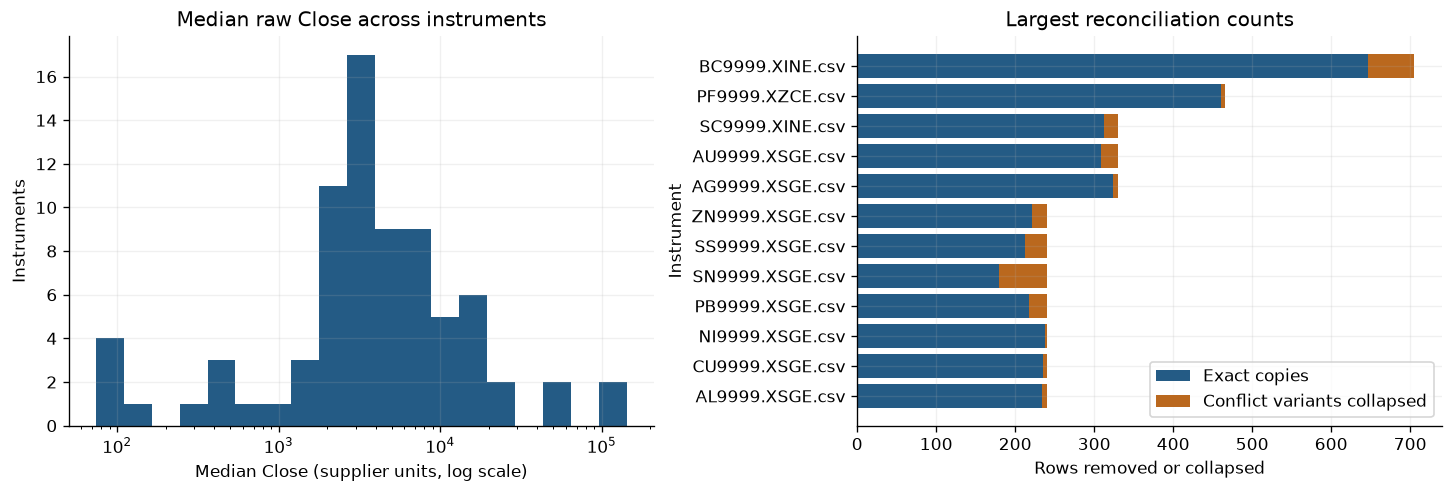

In [12]:
show_table(raw_distribution.loc[raw_distribution.field.eq("close")], "Raw Close distributions by instrument")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
close_medians = raw_distribution.loc[raw_distribution.field.eq("close"), "median"]
axes[0].hist(close_medians[close_medians.gt(0)], bins=np.geomspace(close_medians[close_medians.gt(0)].min(), close_medians.max()*1.001, 20), color="#245b85")
axes[0].set(xscale="log", title="Median raw Close across instruments", xlabel="Median Close (supplier units, log scale)", ylabel="Instruments")
top = quality_summary.nlargest(12, "rows_removed_or_collapsed").sort_values("rows_removed_or_collapsed")
axes[1].barh(top.instrument, top.exact_copies_removed, label="Exact copies", color="#245b85")
axes[1].barh(top.instrument, top.conflict_rows_collapsed, left=top.exact_copies_removed, label="Conflict variants collapsed", color="#ba681e")
axes[1].set(title="Largest reconciliation counts", xlabel="Rows removed or collapsed", ylabel="Instrument")
axes[1].legend()
fig.savefig(QUALITY_DIR / "quality_overview.png", dpi=160)
plt.show()

## Conclusions and outputs
The validated dataset means that schema, chronology, provenance and reconciliation have been checked; it does not certify every quote as economically correct.
No exchange calendar or general contract-specification history is available. The old single-file transition experiments are superseded by the all-instrument contract and segment diagnostics.
The next stage owns feature construction and must consume this dataset, not the raw CSVs.

In [13]:
display(Markdown(
    f"Validated **{len(quality_summary)} instruments** and **{quality_summary.final_observations.sum():,} bars**. "
    f"Removed **{quality_summary.exact_copies_removed.sum():,} exact copies** and collapsed "
    f"**{quality_summary.conflict_rows_collapsed.sum():,} redundant variants**, introducing "
    f"**{quality_summary.new_unknown_cells.sum():,} unknown field values**. "
    f"Flagged **{quality_summary.invalid_rows.sum():,} invalid-value rows** without deleting them."))
display(Markdown("**Next:** run `02_research_statistics_features.ipynb`.\n\n"
    "Outputs: `artifacts/clean_market_data.parquet`, `artifacts/data_quality_summary.csv`, "
    "`artifacts/data_manifest.json`, and detailed evidence in `artifacts/quality/`."))

Validated **77 instruments** and **44,011,860 bars**. Removed **7,636 exact copies** and collapsed **404 redundant variants**, introducing **430 unknown field values**. Flagged **15 invalid-value rows** without deleting them.

**Next:** run `02_research_statistics_features.ipynb`.

Outputs: `artifacts/clean_market_data.parquet`, `artifacts/data_quality_summary.csv`, `artifacts/data_manifest.json`, and detailed evidence in `artifacts/quality/`.